(sec-13-2)=
# 13.2 Spectral Analysis of the EEG

When Hans Berger first described the human EEG in 1929, the observation that made the method famous was, in modern terms, a spectral one: a regular rhythm near 10 Hz over the back of the head that appeared with closed eyes and disappeared when the eyes opened. Most quantitative EEG measures used today are still spectral. A sleep laboratory tracks the shift of power into the delta band as sleep deepens; an anesthesia monitor follows the spectral edge frequency and the spectral entropy of the frontal EEG; a neurologist assessing encephalopathy looks for slowing of the posterior dominant rhythm; and much of the research on aging and neuropsychiatric conditions compares band powers between groups.

The tools are already in place. [Section 7.3](../ch12_spectral_estimation/03_nonparametric_psd.ipynb) introduced the Welch estimator and showed, briefly, that the alpha peak is larger with eyes closed. Here I take that idea as the starting point and build the full set of spectral descriptors an EEG analyst uses: absolute and relative band power, the alpha blocking ratio and its scalp topography, the peak alpha frequency, the aperiodic $1/f$ background, the spectral edge frequency, spectral entropy, Hjorth's time-domain parameters and time-resolved band power. Each measure is derived, checked numerically, and computed on the same two real recordings from eegmmidb {cite:p}`schalk2004,goldberger2000`: one minute of rest with eyes open (R01) and one minute with eyes closed (R02).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import mne
from scipy import signal

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
rng = np.random.default_rng(42)
mne.set_log_level("ERROR")

(sec-13-2-1)=
## 13.2.1 Welch PSDs of a Multichannel Recording

We load both runs, convert them to microvolts and keep the referential montage of the recording. As [Section 13.1.4](01_eeg_fundamentals.ipynb) showed, every spectral number depends on the montage; I use the referential data here and point out where a common average reference would change the conclusions.

In [2]:
def load_run(run):
    """Read one eegmmidb run of subject S001 with standard names and 10-05 positions."""
    raw = mne.io.read_raw_edf(f"../data/eegmmidb/S001{run}.edf", preload=True)
    mne.datasets.eegbci.standardize(raw)
    raw.set_montage("standard_1005")
    raw.crop(tmax=60.0, include_tmax=False)  # the files end with ~1 s of zero padding
    return raw


raw_open, raw_closed = load_run("R01"), load_run("R02")
fs = raw_closed.info["sfreq"]
ch_names = raw_closed.ch_names
idx = {name: k for k, name in enumerate(ch_names)}
eeg = {"Eyes open": raw_open.get_data() * 1e6, "Eyes closed": raw_closed.get_data() * 1e6}   # uV
print(f"{len(ch_names)} channels, {eeg['Eyes closed'].shape[1]} samples per run at {fs:.0f} Hz")

64 channels, 9600 samples per run at 160 Hz


The Welch estimator cuts the record into overlapping segments of length $L$, multiplies each by a window, averages the segment periodograms and scales the result to a one-sided density in µV²/Hz. With hop $D$ between segments, a record of $N$ samples yields

$$
K = \left\lfloor \frac{N - L}{D} \right\rfloor + 1
$$

segments. I use 4-s Hann windows ($L = 640$ samples) with 50% overlap ($D = 320$), so for $N = 9600$ we get $K = \lfloor 8960/320 \rfloor + 1 = 29$ segments. The bin spacing is $f_s/L = 0.25$ Hz, fine enough to locate an alpha peak, and averaging 29 overlapping periodograms reduces the relative standard deviation of each PSD value from about 100% (a single periodogram) to about 20%. Longer segments would sharpen the frequency grid but leave fewer segments to average; that bias–variance trade-off is the subject of [Section 7.3](../ch12_spectral_estimation/03_nonparametric_psd.ipynb).

In [3]:
nperseg = int(4 * fs)
psd = {}
for cond, x in eeg.items():
    f, psd[cond] = signal.welch(x, fs, window="hann", nperseg=nperseg, noverlap=nperseg // 2, axis=1)
df = f[1] - f[0]
n_seg = (eeg["Eyes closed"].shape[1] - nperseg) // (nperseg // 2) + 1
print(f"Segments averaged: {n_seg}, frequency spacing: {df:.2f} Hz")

Segments averaged: 29, frequency spacing: 0.25 Hz


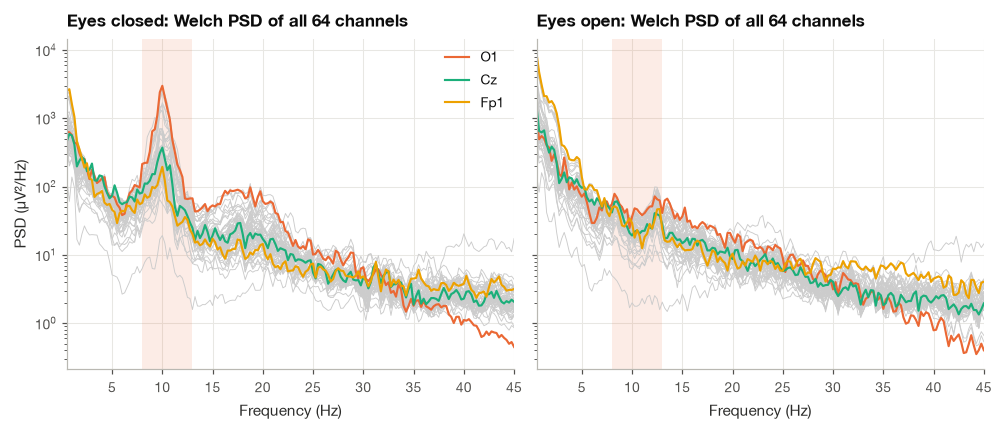

In [4]:
highlight = {"O1": C[1], "Cz": C[2], "Fp1": C[3]}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
band = (f >= 0.5) & (f <= 45)
for ax, cond in zip(axes, ("Eyes closed", "Eyes open")):
    ax.semilogy(f[band], psd[cond][:, band].T, color="0.8", lw=0.6)
    for name, color in highlight.items():
        ax.semilogy(f[band], psd[cond][idx[name], band], color=color, lw=1.4, label=name)
    ax.axvspan(8, 13, color=C[1], alpha=0.12, lw=0)
    ax.set(xlabel="Frequency (Hz)", title=f"{cond}: Welch PSD of all 64 channels", xlim=(0.5, 45))
axes[0].set_ylabel("PSD (µV²/Hz)")
axes[0].legend(loc="upper right")
plt.show()

The gray curves are the 64 channels and the colored curves three electrodes from back to front. With eyes closed, the occipital spectrum (O1) has a sharp peak at 10 Hz rising more than an order of magnitude above its surroundings; the peak shrinks at Cz and is barely visible at Fp1. With eyes open the peak almost disappears. Every channel shares the same overall shape: power falls steadily with frequency, a background we model explicitly in [Section 13.2.4](#sec-13-2-4). One channel (T10) lies far below all the others in both runs; its power is so low at every frequency that I suspect a recording problem at that electrode rather than anything physiological. The frontopolar channel has extra low-frequency power from eye movements and blinks, particularly with the eyes open.

(sec-13-2-2)=
## 13.2.2 Absolute and Relative Band Power

The power of a stationary signal in a frequency band $[f_1, f_2]$ is the area under its one-sided PSD over that band:

(eq-13-5)=
\begin{equation*}
P_{[f_1, f_2]} = \int_{f_1}^{f_2} S_x(f)\, df \;\approx\; \sum_{k:\, f_1 \le f_k \le f_2} \hat{S}_x(f_k)\,\Delta f , \tag{13.5}
\end{equation*}

where $\Delta f = f_s / L$ is the bin spacing. The sum is a rectangle-rule approximation of the integral, accurate when the PSD changes little across one bin. The units are µV²/Hz × Hz = µV², the variance of the signal in that band. **Relative band power** divides by the power over a broad reference range, here 1 to 40 Hz:

$$
P^{\text{rel}}_{[f_1, f_2]} = \frac{P_{[f_1, f_2]}}{P_{[1, 40]}} .
$$

Relative power removes the overall scale, which varies between people and electrodes for reasons unrelated to brain activity (skull thickness, electrode impedance, the reference), and lets us compare spectral *shapes*.

Equation (13.5) has a direct time-domain interpretation. By Parseval's theorem, the variance of the signal after an ideal band-pass filter equals the integral of its PSD over the passband. We can check this with a sharp zero-phase filter: the variance of the alpha-filtered O1 signal should match the alpha band power computed from the PSD.

In [5]:
def band_power(f, psd, f_lo, f_hi):
    """Integrate a one-sided PSD over [f_lo, f_hi] with the rectangle rule (equation 20.5)."""
    mask = (f >= f_lo) & (f <= f_hi)
    return psd[..., mask].sum(axis=-1) * (f[1] - f[0])


o1_closed = eeg["Eyes closed"][idx["O1"]]
sos_alpha = signal.butter(8, [8, 13], btype="bandpass", fs=fs, output="sos")
alpha_wave = signal.sosfiltfilt(sos_alpha, o1_closed)
print(f"Alpha power from the PSD (eq. 20.5)    : {band_power(f, psd['Eyes closed'][idx['O1']], 8, 13):7.1f} uV^2")
print(f"Variance of the alpha-filtered signal  : {alpha_wave.var():7.1f} uV^2")

Alpha power from the PSD (eq. 20.5)    :  3697.6 uV^2
Variance of the alpha-filtered signal  :  3655.8 uV^2


The two estimates agree to within a few percent; the residual difference comes from the filter's finite transition bands and the edge bins of the sum. Now the band table for O1 in both conditions:

In [6]:
bands = {"Delta": (1, 4), "Theta": (4, 8), "Alpha": (8, 13), "Beta": (13, 30), "Gamma": (30, 40)}

rows = []
for cond in ("Eyes closed", "Eyes open"):
    p_o1 = psd[cond][idx["O1"]]
    total = band_power(f, p_o1, 1, 40)
    for name, (lo, hi) in bands.items():
        p = band_power(f, p_o1, lo, hi)
        rows.append({"Condition": cond, "Band": f"{name} ({lo}-{hi} Hz)",
                     "Absolute (uV^2)": round(p, 1), "Relative (%)": round(100 * p / total, 1)})
table = pd.DataFrame(rows).pivot(index="Band", columns="Condition")
table.loc[[f"{n} ({lo}-{hi} Hz)" for n, (lo, hi) in bands.items()]]

Absolute (uV^2)           Relative (%)          
Condition            Eyes closed Eyes open  Eyes closed Eyes open
Band                                                             
Delta (1-4 Hz)             810.0     884.5         14.8      51.6
Theta (4-8 Hz)             374.7     263.9          6.8      15.4
Alpha (8-13 Hz)           3697.6     266.0         67.5      15.5
Beta (13-30 Hz)            670.0     330.4         12.2      19.3
Gamma (30-40 Hz)            27.8      24.1          0.5       1.4

With eyes closed, the alpha band holds about two thirds of the 1–40 Hz power at O1. With eyes open its absolute power drops by more than an order of magnitude and its share falls to roughly one sixth, while the delta, theta and beta bands change much less in absolute terms. Their *relative* powers all rise, simply because the denominator has shrunk. This is the main trap of relative band power: an increase in relative beta can mean more beta or less of something else, and I always report absolute values alongside relative ones.

(sec-13-2-3)=
## 13.2.3 Alpha Blocking and Its Topography

### The Berger effect at the occipital electrodes

The suppression of the posterior alpha rhythm by eye opening is called **alpha blocking**, or the Berger effect. The physiology is still debated in its details, but the broad picture is that the alpha rhythm reflects synchronized activity in thalamocortical circuits of visual cortex when it is not processing visual input; opening the eyes, and visual attention more generally, desynchronizes these circuits and, by the argument of [Section 13.1.1](01_eeg_fundamentals.ipynb), shrinks the scalp signal. We quantify the effect at the three occipital electrodes with the ratio of alpha band powers, also expressed in decibels. To see how much the number depends on the montage, the last column repeats the ratio after re-referencing both runs to the common average.

In [7]:
psd_car = {}
for cond, raw in (("Eyes open", raw_open), ("Eyes closed", raw_closed)):
    x_car = raw.copy().set_eeg_reference("average").get_data() * 1e6
    psd_car[cond] = signal.welch(x_car, fs, window="hann", nperseg=nperseg, noverlap=nperseg // 2, axis=1)[1]

rows = []
for name in ("O1", "Oz", "O2"):
    a_closed = band_power(f, psd["Eyes closed"][idx[name]], 8, 13)
    a_open = band_power(f, psd["Eyes open"][idx[name]], 8, 13)
    ratio_car = (band_power(f, psd_car["Eyes closed"][idx[name]], 8, 13)
                 / band_power(f, psd_car["Eyes open"][idx[name]], 8, 13))
    rows.append({"Channel": name, "Alpha, eyes closed (uV^2)": round(a_closed),
                 "Alpha, eyes open (uV^2)": round(a_open), "Ratio": round(a_closed / a_open, 1),
                 "Ratio (dB)": round(10 * np.log10(a_closed / a_open), 1),
                 "Ratio, common average": round(ratio_car, 1)})
pd.DataFrame(rows).set_index("Channel")

,"Alpha, eyes closed (uV^2)","Alpha, eyes open (uV^2)",Ratio,Ratio (dB),"Ratio, common average"
Channel,,,,,
O1,3698,266,13.9,11.4,22.3
Oz,2896,238,12.1,10.8,18.9
O2,3349,244,13.7,11.4,20.1


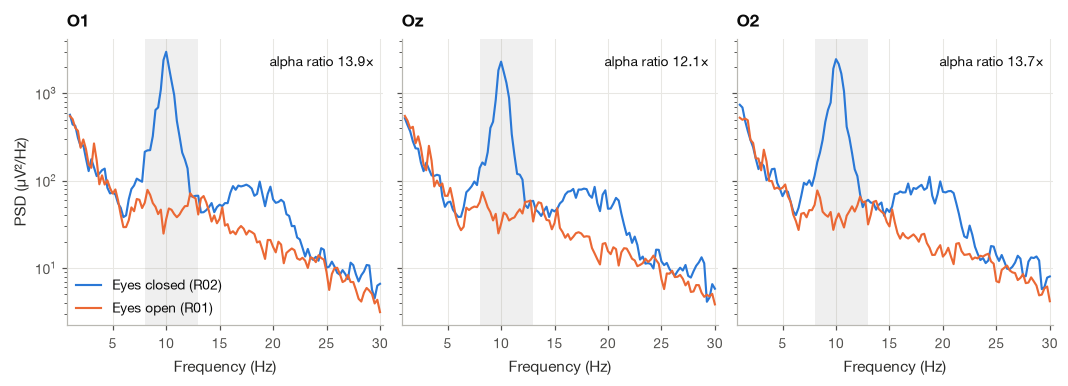

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.4), sharey=True)
band = (f >= 1) & (f <= 30)
for ax, name in zip(axes, ("O1", "Oz", "O2")):
    ax.semilogy(f[band], psd["Eyes closed"][idx[name], band], color=C[0], label="Eyes closed (R02)")
    ax.semilogy(f[band], psd["Eyes open"][idx[name], band], color=C[1], label="Eyes open (R01)")
    ax.axvspan(8, 13, color="0.5", alpha=0.12, lw=0)
    ratio = band_power(f, psd["Eyes closed"][idx[name]], 8, 13) / band_power(f, psd["Eyes open"][idx[name]], 8, 13)
    ax.text(0.97, 0.95, f"alpha ratio {ratio:.1f}×", transform=ax.transAxes, ha="right", va="top", fontsize=9)
    ax.set(xlabel="Frequency (Hz)", title=f"{name}")
axes[0].set_ylabel("PSD (µV²/Hz)")
axes[0].legend(loc="lower left")
plt.show()

At all three electrodes alpha power is twelve to fourteen times larger with the eyes closed, about 11 dB. The blocking is specific: below 7 Hz and above 15 Hz the two spectra nearly coincide. Two cautions apply. First, R01 and R02 are separate one-minute runs, so part of the difference could reflect drowsiness or attention drifting between runs rather than eye state alone. Second, the ratio depends on the montage: re-referencing to the common average removes alpha that is shared with the reference and increases the ratio at O1 from about 14 to about 22, and at Oz and O2 to about 19 and 20. The direction and location of the effect are robust; its exact size is not a physiological constant.

### Topographic maps

A topographic map interpolates a per-channel quantity across the scalp. We compute alpha power at every electrode for both conditions, convert it to decibels relative to 1 µV² so that one color scale covers both, and draw the maps with `mne.viz.plot_topomap` {cite:p}`gramfort2013`. A third map shows the blocking ratio in decibels.

In [9]:
alpha_db = {cond: 10 * np.log10(band_power(f, psd[cond], 8, 13)) for cond in psd}
blocking_db = alpha_db["Eyes closed"] - alpha_db["Eyes open"]
for cond, values in alpha_db.items():
    top = np.argsort(values)[::-1][:4]
    print(f"{cond:<12s} strongest alpha: " + ", ".join(f"{ch_names[k]} {values[k]:.1f} dB" for k in top))
top = np.argsort(blocking_db)[::-1][:4]
print("Largest blocking ratio : " + ", ".join(f"{ch_names[k]} {blocking_db[k]:.1f} dB" for k in top))
print(f"Smallest blocking ratio: {ch_names[np.argmin(blocking_db)]} {blocking_db.min():.1f} dB")

Eyes open    strongest alpha: O1 24.2 dB, O2 23.9 dB, Oz 23.8 dB, PO3 23.7 dB
Eyes closed  strongest alpha: PO8 36.0 dB, O1 35.7 dB, O2 35.2 dB, Oz 34.6 dB
Largest blocking ratio : PO8 13.1 dB, O1 11.4 dB, O2 11.4 dB, PO4 11.1 dB
Smallest blocking ratio: T9 2.1 dB


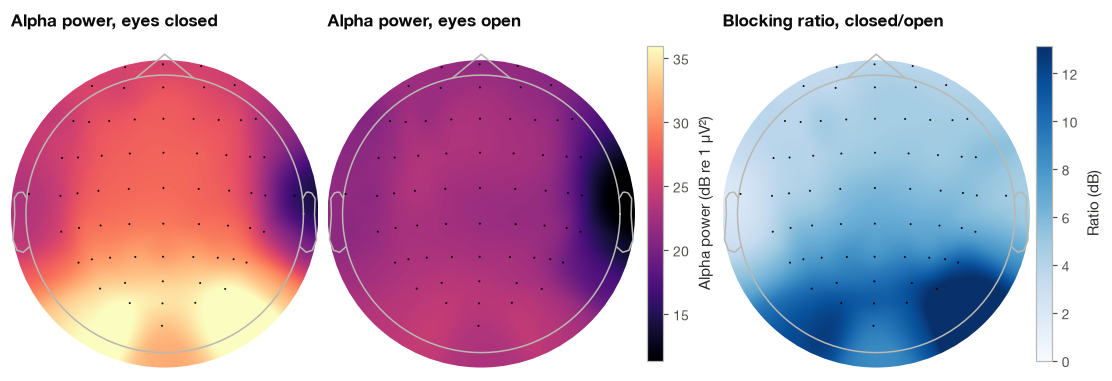

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.9))
vlim = (min(v.min() for v in alpha_db.values()), max(v.max() for v in alpha_db.values()))
for ax, cond in zip(axes[:2], ("Eyes closed", "Eyes open")):
    im, _ = mne.viz.plot_topomap(alpha_db[cond], raw_closed.info, axes=ax, show=False, cmap="magma",
                                 vlim=vlim, contours=0, sensors=True)
    ax.set_title(f"Alpha power, {cond.lower()}")
cbar = fig.colorbar(im, ax=axes[:2], shrink=0.75, pad=0.02)
cbar.set_label("Alpha power (dB re 1 µV²)")
im2, _ = mne.viz.plot_topomap(blocking_db, raw_closed.info, axes=axes[2], show=False, cmap="Blues",
                              contours=0, sensors=True)
axes[2].set_title("Blocking ratio, closed/open")
cbar2 = fig.colorbar(im2, ax=axes[2], shrink=0.75, pad=0.02)
cbar2.set_label("Ratio (dB)")
plt.show()

Alpha power with eyes closed forms a clear posterior maximum over the occipital and right parieto-occipital electrodes (PO8, O1, O2, about 35 to 36 dB), falling by roughly 10 dB towards the frontopolar sites and further at the right temporal electrodes. With eyes open the map is flatter and lower everywhere, within a few decibels of 22 to 24 dB over most of the scalp. The dark spot at the right temporal edge of both maps is T10, the electrode I flagged in the first figure. The blocking ratio is largest over the same posterior region and smallest (2 to 4 dB) at the left temporal and frontopolar edges, where the "alpha" band contains mostly non-alpha activity that does not change with eye state. This posterior distribution is the textbook signature of the alpha rhythm, and it is a useful sanity check: a "posterior dominant rhythm" that is maximal frontally should make you suspect a montage error or an artifact.

(sec-13-2-4)=
## 13.2.4 The Aperiodic 1/f Component and the Peak Alpha Frequency

### A straight line in log–log coordinates

Outside the alpha peak, every spectrum in the first figure falls smoothly with frequency. Neural power spectra are often described as the sum of an **aperiodic** component, roughly a power law, and **periodic** components (peaks) on top of it. The power-law model is

$$
S(f) = \frac{A}{f^{\beta}} \quad\Longrightarrow\quad \log_{10} S(f) = \log_{10} A - \beta \log_{10} f ,
$$

so on log–log axes it is a straight line with slope $-\beta$. The exponent $\beta$ (often between 1 and 2 for scalp EEG) and the offset $\log_{10}A$ describe the background. Changes of the exponent with age, task and drugs have been reported and have been proposed to reflect the balance of excitation and inhibition in cortex, an interpretation that is still debated. In practice the most important reason to model the background is simpler: a band power or a peak frequency measured without accounting for it mixes periodic and aperiodic changes {cite:p}`donoghue2020`.

### Fitting the line by least squares

Write $u_k = \log_{10} f_k$ and $y_k = \log_{10}\hat{S}(f_k)$ for the bins we include, and fit $y_k \approx c - \beta u_k$. The least-squares criterion is

$$
J(c, \beta) = \sum_k \big(y_k - c + \beta u_k\big)^2 .
$$

Setting $\partial J/\partial c = 0$ gives $\sum_k (y_k - c + \beta u_k) = 0$, that is, $c = \bar{y} + \beta\bar{u}$: the line passes through the centroid $(\bar u, \bar y)$. Substituting this into $\partial J/\partial \beta = 0$, which reads $\sum_k u_k (y_k - c + \beta u_k) = 0$, and subtracting $\bar u$ times the first condition,

(eq-13-6)=
\begin{equation*}
\begin{aligned}
\sum_k (u_k - \bar u)\big(y_k - \bar y + \beta (u_k - \bar u)\big) &= 0 \\
\hat\beta &= -\frac{\sum_k (u_k - \bar u)(y_k - \bar y)}{\sum_k (u_k - \bar u)^2}, \qquad \hat c = \bar y + \hat\beta \bar u .
\end{aligned} \tag{13.6}
\end{equation*}

The slope is minus the covariance of the log-frequency and the log-power divided by the variance of the log-frequency. We fit over 2–40 Hz and **exclude** the alpha region (7–14 Hz), where the peak would pull the line upwards, and the 60 Hz region, which lies outside the range anyway. One subtlety: linearly spaced bins crowd together at high frequencies on a log axis, so an unweighted fit is dominated by the upper part of the range. For a clean power law this does not bias the estimate, but it does make the fit more sensitive to muscle activity at high frequencies.

In [11]:
def fit_aperiodic(f, psd, f_range=(2, 40), exclude=((7, 14),)):
    """Least-squares power-law fit in log-log coordinates (equation 20.6); returns (beta, c, mask)."""
    mask = (f >= f_range[0]) & (f <= f_range[1])
    for lo, hi in exclude:
        mask &= ~((f >= lo) & (f <= hi))
    u, y = np.log10(f[mask]), np.log10(psd[mask])
    beta = -np.sum((u - u.mean()) * (y - y.mean())) / np.sum((u - u.mean()) ** 2)
    return beta, y.mean() + beta * u.mean(), mask


aperiodic = {}
for cond in ("Eyes closed", "Eyes open"):
    beta, c, mask = fit_aperiodic(f, psd[cond][idx["O1"]])
    aperiodic[cond] = (beta, c)
    slope_np = np.polyfit(np.log10(f[mask]), np.log10(psd[cond][idx["O1"], mask]), 1)[0]
    print(f"{cond:<12s}: beta = {beta:.2f} (np.polyfit slope {slope_np:.2f}), offset log10 A = {c:.2f}")

ranges = [(1, 40), (2, 40), (2, 30)]
betas = [fit_aperiodic(f, psd["Eyes closed"][idx["O1"]], f_range=r)[0] for r in ranges]
print("Eyes closed, exponent by fit range: " + ", ".join(f"{lo}-{hi} Hz: {b:.2f}" for (lo, hi), b in zip(ranges, betas)))

Eyes closed : beta = 1.69 (np.polyfit slope -1.69), offset log10 A = 3.33
Eyes open   : beta = 1.74 (np.polyfit slope -1.74), offset log10 A = 3.24
Eyes closed, exponent by fit range: 1-40 Hz: 1.56, 2-40 Hz: 1.69, 2-30 Hz: 1.03


Our least-squares slope agrees with `np.polyfit` to the printed precision. Over 2–40 Hz the exponent is about 1.7 in both conditions: the background barely changes with eye state, and what changes is the peak on top of it.

The last line is a warning, though. The same eyes-closed spectrum gives $\beta \approx 1.0$ if we stop the fit at 30 Hz. The O1 spectrum is not one straight line on log–log axes: it bends downwards above about 30 Hz, and the broad hump between 15 and 25 Hz lifts the middle of the range. A single exponent summarizes the spectrum *over a stated range*, and two exponents can only be compared if they were fitted over the same range in the same way. Subtracting the fitted line from the log-spectrum leaves the **periodic** part, the height of each peak above the background in decibels.

### The peak alpha frequency

The **peak alpha frequency** (PAF) is the frequency of the alpha maximum. In healthy adults it typically lies between about 9 and 11 Hz; it is lower in children, declines in older age and has been reported to be lower in a number of neurological conditions. The simplest estimate is the frequency of the largest PSD bin between 7 and 14 Hz, but its precision is limited to the bin spacing (0.25 Hz). Two refinements are common.

**Parabolic interpolation.** Fit a parabola $y(\delta) = a\delta^2 + b\delta + c$ through the log-PSD at the peak bin and its two neighbors, placed at $\delta = -1, 0, +1$ (in bins). The three conditions $y(0) = y_0$, $y(1) = y_+$, $y(-1) = y_-$ give $c = y_0$, $b = (y_+ - y_-)/2$ and $a = (y_+ + y_-)/2 - y_0$. The vertex lies where $dy/d\delta = 2a\delta + b = 0$:

(eq-13-7)=
\begin{equation*}
\delta^{*} = -\frac{b}{2a} = \frac{y_- - y_+}{2\,(y_- - 2y_0 + y_+)}, \qquad \hat f_{\text{peak}} = f_{k_0} + \delta^{*}\Delta f . \tag{13.7}
\end{equation*}

**Center of gravity.** The power-weighted mean frequency of the alpha band, $f_{\text{CoG}} = \sum_k f_k S_k / \sum_k S_k$ over 8–13 Hz, uses every bin in the band and is less sensitive to noise, but it is pulled towards the middle of the band when the peak is weak. With no peak at all it still returns a number, somewhere near the middle of the band.

When the alpha peak is weak, as with eyes open, the largest bin may simply be the point where the falling background crosses into the band. Searching for the maximum of the *flattened* spectrum (after removing the aperiodic fit) avoids that trap, but it raises a second question: is the maximum a peak at all, or just the high end of a slope? I use a simple test. The largest flattened value in 7–14 Hz must rise at least 3 dB (a doubling of power) above the flattened spectrum at *both* ends of the search band. A genuine alpha peak passes easily; a maximum sitting at the foot of a neighboring hump does not. When the test fails, I report the peak alpha frequency as missing rather than as a number.

In [12]:
def parabolic_peak(f, y, f_lo=7, f_hi=14):
    """Bin and parabola-interpolated frequency of the maximum of a log spectrum y in [f_lo, f_hi] (eq. 20.7)."""
    band_idx = np.flatnonzero((f >= f_lo) & (f <= f_hi))
    k0 = band_idx[np.argmax(y[band_idx])]
    y_m, y_0, y_p = y[k0 - 1:k0 + 2]
    delta = (y_m - y_p) / (2 * (y_m - 2 * y_0 + y_p))
    return f[k0], f[k0] + delta * (f[1] - f[0])


def flatten(f, psd, beta, c):
    """Spectrum in dB above the fitted aperiodic line 10*(c - beta*log10 f)."""
    return 10 * np.log10(psd) - 10 * (c - beta * np.log10(np.maximum(f, f[1])))


def peak_rise(f, flat_db, f_lo=7, f_hi=14):
    """Largest flattened value in the band minus the higher of its two edge values (dB)."""
    seg = flat_db[(f >= f_lo) & (f <= f_hi)]
    return seg.max() - max(seg[0], seg[-1])


rows = []
for cond in ("Eyes closed", "Eyes open"):
    p_o1 = psd[cond][idx["O1"]]
    flat = flatten(f, p_o1, *aperiodic[cond])
    raw_bin, interp = parabolic_peak(f, np.log10(p_o1))
    flat_bin, interp_flat = parabolic_peak(f, flat)
    alpha_mask = (f >= 8) & (f <= 13)
    cog = np.sum(f[alpha_mask] * p_o1[alpha_mask]) / np.sum(p_o1[alpha_mask])
    rows.append({"Condition": cond, "Max bin (Hz)": raw_bin, "Parabolic (Hz)": round(interp, 2),
                 "Center of gravity (Hz)": round(cog, 2), "Flattened max (Hz)": round(interp_flat, 2),
                 "Height above fit (dB)": round(flat[f == flat_bin][0], 1),
                 "Rise above band edges (dB)": round(peak_rise(f, flat), 1)})
pd.DataFrame(rows).set_index("Condition")

,Max bin (Hz),Parabolic (Hz),Center of gravity (Hz),Flattened max (Hz),Height above fit (dB),Rise above band edges (dB)
Condition,,,,,,
Eyes closed,10.00,9.96,10.04,9.98,18.3,15.3
Eyes open,8.25,8.31,10.48,13.48,5.5,1.4


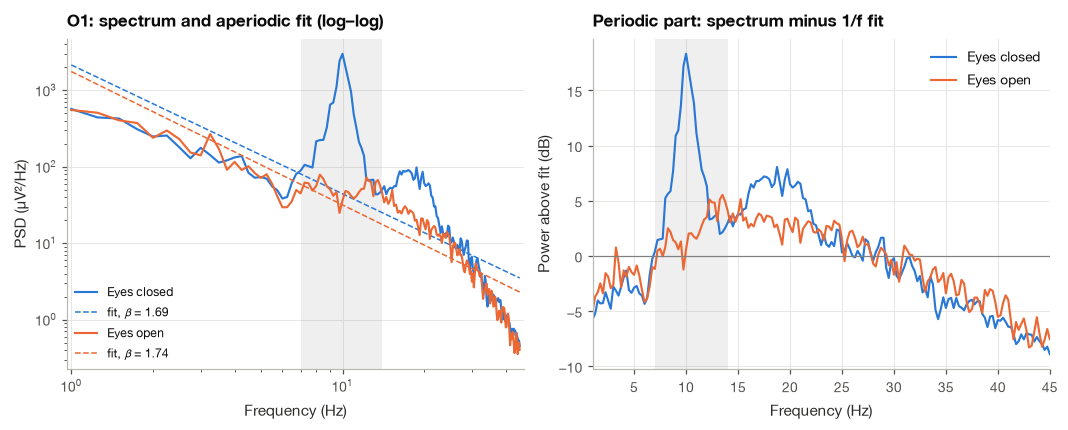

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.8))
fit_band = (f >= 1) & (f <= 45)
for cond, color in (("Eyes closed", C[0]), ("Eyes open", C[1])):
    p_o1 = psd[cond][idx["O1"]]
    beta, c = aperiodic[cond]
    axes[0].loglog(f[fit_band], p_o1[fit_band], color=color, label=f"{cond}")
    axes[0].loglog(f[fit_band], 10 ** (c - beta * np.log10(f[fit_band])), "--", color=color, lw=1,
                   label=rf"fit, $\beta$ = {beta:.2f}")
    flat = 10 * np.log10(p_o1[fit_band]) - 10 * (c - beta * np.log10(f[fit_band]))
    axes[1].plot(f[fit_band], flat, color=color, label=cond)
axes[0].axvspan(7, 14, color="0.5", alpha=0.12, lw=0)
axes[0].set(xlabel="Frequency (Hz)", ylabel="PSD (µV²/Hz)", title="O1: spectrum and aperiodic fit (log–log)")
axes[0].legend(loc="lower left", fontsize=8)
axes[1].axhline(0, color="0.5", lw=0.8)
axes[1].axvspan(7, 14, color="0.5", alpha=0.12, lw=0)
axes[1].set(xlabel="Frequency (Hz)", ylabel="Power above fit (dB)", title="Periodic part: spectrum minus 1/f fit",
            xlim=(1, 45))
axes[1].legend(loc="upper right")
plt.show()

With eyes closed every estimator agrees on a peak alpha frequency of 10.0 Hz to within 0.05 Hz, and the peak stands about 18 dB above the background and 15 dB above the edges of the search band. With eyes open the estimators scatter over five hertz. The largest raw bin is at 8.25 Hz, simply where the falling background enters the band; the center of gravity returns 10.5 Hz, close to the middle of the band; and the flattened maximum lies at 13.5 Hz, on the rising flank of the broad 15–25 Hz hump visible in the right panel. Its rise above the band edges is only about 1.4 dB, so the test fails and the honest answer is that this recording has no measurable alpha peak at O1 with the eyes open. The lesson is general: peak measures are reliable only when there is a clear peak, the flattened spectrum tells you whether there is one, and disagreement between estimators is itself a warning sign.

(sec-13-2-5)=
## 13.2.5 Summary Measures of Spectral Shape: SEF90 and Spectral Entropy

Clinical monitors often reduce the whole spectrum to a single number that tracks a slow change of state, for example the deepening of general anesthesia, during which EEG power moves towards lower frequencies.

### Spectral edge frequency

The **spectral edge frequency** SEF$_q$ is the frequency below which a fraction $q$ of the power in an analysis range $[f_{\text{lo}}, f_{\text{hi}}]$ lies:

$$
\int_{f_{\text{lo}}}^{\text{SEF}_q} S(f)\, df = q \int_{f_{\text{lo}}}^{f_{\text{hi}}} S(f)\, df .
$$

SEF90 and SEF95 ($q = 0.9, 0.95$) are the usual choices. We compute the cumulative sum of the PSD bins and interpolate linearly to find where it crosses the fraction $q$.

### Spectral entropy

The **spectral entropy** treats the normalized PSD as a probability distribution over frequency bins. With $p_k = S_k / \sum_i S_i$ over the $K$ bins in the analysis range, it is the Shannon entropy normalized by its maximum $\ln K$:

(eq-13-8)=
\begin{equation*}
H_{\text{sp}} = -\frac{1}{\ln K}\sum_{k=1}^{K} p_k \ln p_k , \qquad 0 \le H_{\text{sp}} \le 1 . \tag{13.8}
\end{equation*}

A flat spectrum ($p_k = 1/K$ for all $k$) gives $-\frac{1}{\ln K}\, K \cdot \frac{1}{K}\ln\frac{1}{K} = 1$. A spectrum with all its power in one bin gives $0$, because $1 \cdot \ln 1 = 0$ and the other terms vanish (using $p\ln p \to 0$ as $p \to 0$). A dominant rhythm lowers the entropy; broadband, irregular activity raises it. Entropy measures of the signal itself, rather than its spectrum, appear in Section 26.2.

We check both definitions on signals whose answers we know: white noise (flat spectrum, so the entropy should be close to one and SEF90 should be at 90% of the range) and a pure 10 Hz sinusoid (entropy close to zero, SEF90 at 10 Hz).

In [14]:
def spectral_edge(f, psd, q=0.9, f_range=(1, 40)):
    """Frequency below which a fraction q of the power in f_range lies (linear interpolation)."""
    mask = (f >= f_range[0]) & (f <= f_range[1])
    cum = np.cumsum(psd[mask])
    return np.interp(q * cum[-1], cum, f[mask])


def spectral_entropy(f, psd, f_range=(1, 40)):
    """Normalized Shannon entropy of the PSD over f_range (equation 20.8)."""
    mask = (f >= f_range[0]) & (f <= f_range[1])
    p = psd[mask] / psd[mask].sum()
    p = p[p > 0]
    return -np.sum(p * np.log(p)) / np.log(mask.sum())


t_test = np.arange(int(60 * fs)) / fs
for name, x in [("White noise", rng.normal(size=t_test.size)), ("10 Hz sinusoid", np.sin(2 * np.pi * 10 * t_test))]:
    f_t, p_t = signal.welch(x, fs, nperseg=nperseg)
    print(f"{name:<15s} SEF90 = {spectral_edge(f_t, p_t):5.2f} Hz   spectral entropy = {spectral_entropy(f_t, p_t):.3f}")

White noise     SEF90 = 36.24 Hz   spectral entropy = 0.997
10 Hz sinusoid  SEF90 = 10.10 Hz   spectral entropy = 0.172


White noise gives an entropy of 0.997 (not exactly one, because the Welch estimate fluctuates from bin to bin) and an SEF90 of 36.2 Hz, close to 36.1 Hz, where 90% of the 1–40 Hz range ends. The sinusoid gives an SEF90 of 10.1 Hz and an entropy of 0.17, not zero, because the Hann window spreads the line over a few bins and leaves small sidelobe values elsewhere. On the EEG:

In [15]:
for cond in ("Eyes closed", "Eyes open"):
    p_o1 = psd[cond][idx["O1"]]
    print(f"O1, {cond:<12s}: SEF90 = {spectral_edge(f, p_o1):5.2f} Hz, SEF95 = {spectral_edge(f, p_o1, 0.95):5.2f} Hz, "
          f"spectral entropy = {spectral_entropy(f, p_o1):.3f}")

O1, Eyes closed : SEF90 = 15.66 Hz, SEF95 = 19.05 Hz, spectral entropy = 0.720
O1, Eyes open   : SEF90 = 17.64 Hz, SEF95 = 22.46 Hz, spectral entropy = 0.815


With eyes closed, the dominant alpha peak concentrates power, so the entropy is lower (0.72) and the spectral edge sits lower (15.7 Hz). Opening the eyes removes most of the peak, and both measures move up (0.81 and 17.6 Hz). Note what these numbers cannot tell us: a lower SEF90 could come from more alpha or from more delta, two very different states. Single-number descriptors are useful for tracking change within one person; they are poor at explaining *why* a spectrum changed.

(sec-13-2-6)=
## 13.2.6 Hjorth Parameters

In 1970 Bo Hjorth proposed three descriptors computed entirely in the time domain, cheap enough for the analog electronics and early computers of the time {cite:p}`hjorth1970`. For a zero-mean signal $x(t)$ with derivatives $x'$ and $x''$:

(eq-13-9)=
\begin{equation*}
\text{Activity} = \sigma_x^2, \qquad
\text{Mobility} = \sqrt{\frac{\sigma_{x'}^2}{\sigma_x^2}}, \qquad
\text{Complexity} = \frac{\text{Mobility}(x')}{\text{Mobility}(x)} = \sqrt{\frac{\sigma_{x''}^2\,\sigma_x^2}{\left(\sigma_{x'}^2\right)^2}} . \tag{13.9}
\end{equation*}

They look arbitrary until we translate them into the frequency domain. Differentiation multiplies the Fourier transform by $j2\pi f$, so the PSD of $x'$ is $(2\pi f)^2 S_x(f)$. Integrating over frequency (Parseval again),

$$
\sigma_{x'}^2 = \int_0^{\infty} (2\pi f)^2 S_x(f)\, df \quad\Longrightarrow\quad
\text{Mobility} = 2\pi \sqrt{\frac{\int f^2 S_x(f)\, df}{\int S_x(f)\, df}} .
$$

**Mobility is $2\pi$ times the RMS frequency of the spectrum**, the square root of its second moment. Dividing by $2\pi$ expresses it in hertz. **Complexity** compares the RMS frequency of the derivative's spectrum with that of the signal's spectrum; it measures how far the spectrum is from a single line, in effect its spread.

**Example 13.2.1.** Compute the three parameters for $x(t) = A\sin(\omega_0 t)$.

The variance of a sinusoid of amplitude $A$ is $A^2/2$, so Activity $= A^2/2$. Its derivative $x' = A\omega_0\cos(\omega_0 t)$ has variance $A^2\omega_0^2/2$, so

$$
\text{Mobility} = \sqrt{\frac{A^2\omega_0^2/2}{A^2/2}} = \omega_0 .
$$

The second derivative $x'' = -A\omega_0^2 \sin(\omega_0 t)$ has variance $A^2\omega_0^4/2$, so $\text{Mobility}(x') = \sqrt{(A^2\omega_0^4/2)/(A^2\omega_0^2/2)} = \omega_0$ and Complexity $= \omega_0/\omega_0 = 1$.

A pure sinusoid has the smallest possible complexity. Writing $m_n = \int f^n S_x(f)\,df$ for the spectral moments, Complexity $= \sqrt{m_4 m_0}/m_2$, and the Cauchy–Schwarz inequality applied to the functions $f^2\sqrt{S_x}$ and $\sqrt{S_x}$ gives $m_2^2 \le m_4 m_0$, so Complexity $\ge 1$, with equality only when all the power sits at a single frequency. Any spread of the spectrum makes it larger.

On sampled data we approximate derivatives by first differences multiplied by $f_s$. The first difference has frequency response $1 - e^{-j\Omega}$ with magnitude $2\sin(\Omega/2)$, not $\Omega$, so for a sinusoid the computed mobility is $2 f_s\sin(\Omega_0/2)$ instead of $\omega_0$. For 10 Hz at 160 Hz, $\Omega_0 = 0.393$ rad/sample and the error is $1 - 2\sin(\Omega_0/2)/\Omega_0 \approx 0.6\%$, small for EEG frequencies but worth knowing.

In [16]:
def hjorth(x, fs):
    """Hjorth activity, mobility (Hz) and complexity using first differences (equation 20.9)."""
    dx = np.diff(x) * fs
    ddx = np.diff(dx) * fs
    activity = x.var()
    mobility = np.sqrt(dx.var() / x.var())
    complexity = np.sqrt(ddx.var() / dx.var()) / mobility
    return activity, mobility / (2 * np.pi), complexity


sine = 50 * np.sin(2 * np.pi * 10 * t_test)
act, mob, comp = hjorth(sine, fs)
omega0 = 2 * np.pi * 10 / fs
print(f"10 Hz sinusoid, A = 50: activity {act:.1f} (A^2/2 = 1250.0), mobility {mob:.3f} Hz, complexity {comp:.4f}")
print(f"Predicted mobility with first differences: {2 * fs * np.sin(omega0 / 2) / (2 * np.pi):.3f} Hz")

10 Hz sinusoid, A = 50: activity 1250.0 (A^2/2 = 1250.0), mobility 9.935 Hz, complexity 1.0002
Predicted mobility with first differences: 9.936 Hz


For the EEG we first band-pass the signal to 1–40 Hz, because the derivative amplifies high-frequency noise and the variance is dominated by slow drift if it is not removed. The mobility, converted to hertz, can be compared with the RMS frequency computed from the Welch PSD over the same range.

In [17]:
sos_broad = signal.butter(4, [1, 40], btype="bandpass", fs=fs, output="sos")
for cond in ("Eyes closed", "Eyes open"):
    x = signal.sosfiltfilt(sos_broad, eeg[cond][idx["O1"]])
    act, mob, comp = hjorth(x, fs)
    p_o1 = psd[cond][idx["O1"]]
    m = (f >= 1) & (f <= 40)
    f_rms = np.sqrt(np.sum(f[m] ** 2 * p_o1[m]) / np.sum(p_o1[m]))
    print(f"O1, {cond:<12s}: activity {act:7.1f} uV^2, mobility {mob:5.2f} Hz "
          f"(RMS frequency of PSD {f_rms:5.2f} Hz), complexity {comp:.2f}")

O1, Eyes closed : activity  5366.1 uV^2, mobility 10.84 Hz (RMS frequency of PSD 10.94 Hz), complexity 1.40
O1, Eyes open   : activity  1586.3 uV^2, mobility 10.33 Hz (RMS frequency of PSD 10.34 Hz), complexity 1.90


The mobility (about 10–11 Hz) agrees with the RMS frequency computed from the spectrum to within a few percent, confirming the derivation. Activity falls by more than a factor of three when the eyes open, mirroring the alpha loss. Complexity rises from about 1.4 to 1.9: the eyes-closed signal is dominated by one rhythm and is closer to a sinusoid, while the eyes-open signal spreads its power over a wider range of frequencies.

(sec-13-2-7)=
## 13.2.7 Time-Resolved Band Power

Everything so far assumed that the minute of EEG is stationary, so that one spectrum describes it. It is not: the alpha rhythm waxes and wanes over seconds, as the band-filtered trace in [Section 13.1.5](01_eeg_fundamentals.ipynb) showed. The simplest way to follow the change is to repeat the spectral estimate in a **sliding window**. Each window must be short enough to follow the change and long enough to give a usable estimate, the trade-off that Chapter 23 formalizes as the uncertainty principle. I use 2-s windows advanced in steps of 0.25 s, and inside each window a Welch estimate with 1-s Hann segments (three segments at 50% overlap, 1 Hz spacing).

In [18]:
def sliding_band_power(x, fs, win_s=2.0, step_s=0.25, f_band=(8, 13)):
    """Band power, relative power and spectral entropy in sliding windows (Welch within each window)."""
    win, step = int(win_s * fs), int(step_s * fs)
    starts = np.arange(0, x.size - win + 1, step)
    out = np.empty((starts.size, 3))
    for i, s in enumerate(starts):
        f_w, p_w = signal.welch(x[s:s + win], fs, nperseg=int(fs), noverlap=int(fs) // 2)
        a = band_power(f_w, p_w, *f_band)
        out[i] = a, a / band_power(f_w, p_w, 1, 40), spectral_entropy(f_w, p_w)
    return (starts + win / 2) / fs, out


tracks = {cond: sliding_band_power(eeg[cond][idx["O1"]], fs) for cond in ("Eyes closed", "Eyes open")}
for cond, (t_c, vals) in tracks.items():
    a = vals[:, 0]
    print(f"{cond:<12s}: {t_c.size} windows; alpha power median {np.median(a):6.0f} uV^2, "
          f"5th-95th percentile {np.percentile(a, 5):5.0f}-{np.percentile(a, 95):5.0f} uV^2 "
          f"(ratio {np.percentile(a, 95) / np.percentile(a, 5):.1f})")

Eyes closed : 233 windows; alpha power median   3447 uV^2, 5th-95th percentile  1545- 7151 uV^2 (ratio 4.6)
Eyes open   : 233 windows; alpha power median    275 uV^2, 5th-95th percentile   118-  538 uV^2 (ratio 4.6)


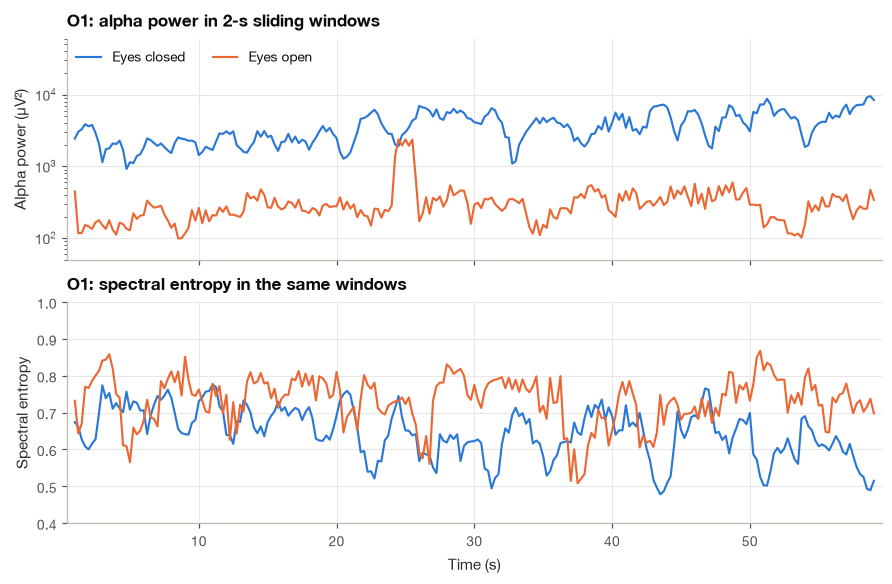

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(8, 5.2), sharex=True)
for cond, color in (("Eyes closed", C[0]), ("Eyes open", C[1])):
    t_c, vals = tracks[cond]
    axes[0].semilogy(t_c, vals[:, 0], color=color, label=cond)
    axes[1].plot(t_c, vals[:, 2], color=color, label=cond)
axes[0].set(ylabel="Alpha power (µV²)", title="O1: alpha power in 2-s sliding windows", ylim=(50, 6e4))
axes[0].legend(loc="upper left", ncols=2)
axes[1].set(xlabel="Time (s)", ylabel="Spectral entropy", title="O1: spectral entropy in the same windows",
            ylim=(0.4, 1.0))
plt.show()

The two conditions are separated at almost every moment, but neither is constant. With eyes closed, alpha power varies by a factor of about 4.6 between its 5th and 95th percentiles, and the spectral entropy moves in the opposite direction, dipping whenever alpha is strong. The exception to the separation is a stretch of about two seconds near 25 s in the eyes-open run, where alpha power at O1 jumps to eyes-closed levels. The frontopolar channels show deflections of more than 600 µV at the same moment, so the most likely explanation is a blink or a brief eye closure; the recording has no annotation that would tell us which. It is a reminder that "eyes open" is an instruction to the subject, not a measurement. A single Welch spectrum averages over all of this. Whether these fluctuations matter depends on the question: for a diagnostic measure of the resting rhythm the average is what we want; for studying attention, drowsiness or responses to events ([Section 13.3](03_event_related_activity.ipynb)) the fluctuations are the signal.

(sec-13-2-8)=
## 13.2.8 A Spectral Report for Eyes Closed versus Eyes Open

To close, we collect every measure of this section into one table, computed the same way for an occipital (O1) and a central (Cz) electrode. Building such a report step by step is the core of most quantitative EEG pipelines.

### Step 1: Choose the channels, the montage and the estimator

We keep everything as above: the referential montage, 4-s Hann windows with 50% overlap, an analysis range of 1–40 Hz for relative power, SEF90 and entropy, an aperiodic fit over 2–40 Hz without the alpha region, and the 1–40 Hz band-passed signal for the Hjorth parameters. Writing these choices down is part of the result, because, as we have seen, several of the numbers change when any of them changes.

### Step 2: Compute the features

In [20]:
def spectral_report(x, fs):
    """All spectral features of this section for one channel of EEG (uV)."""
    f_x, p_x = signal.welch(x, fs, nperseg=int(4 * fs))
    total = band_power(f_x, p_x, 1, 40)
    beta, c, _ = fit_aperiodic(f_x, p_x)
    flat = flatten(f_x, p_x, beta, c)
    paf = parabolic_peak(f_x, flat)[1] if peak_rise(f_x, flat) >= 3 else np.nan
    act, mob, comp = hjorth(signal.sosfiltfilt(sos_broad, x), fs)
    row = {f"{name} abs (uV^2)": band_power(f_x, p_x, lo, hi) for name, (lo, hi) in bands.items()}
    row.update({f"{name} rel (%)": 100 * band_power(f_x, p_x, lo, hi) / total for name, (lo, hi) in bands.items()})
    row.update({"PAF, flattened (Hz)": paf, "Aperiodic exponent": beta,
                "SEF90 (Hz)": spectral_edge(f_x, p_x), "Spectral entropy": spectral_entropy(f_x, p_x),
                "Hjorth activity (uV^2)": act, "Hjorth mobility (Hz)": mob, "Hjorth complexity": comp})
    return row


report = pd.DataFrame({f"{ch} {cond.split()[1]}": spectral_report(eeg[cond][idx[ch]], fs)
                       for ch in ("O1", "Cz") for cond in ("Eyes closed", "Eyes open")})
report.round(2)

,O1 closed,O1 open,Cz closed,Cz open
Delta abs (uV^2),809.99,884.53,757.68,940.70
Theta abs (uV^2),374.66,263.95,334.27,326.57
Alpha abs (uV^2),3697.58,266.03,677.14,171.16
Beta abs (uV^2),669.97,330.42,226.21,174.11
Gamma abs (uV^2),27.77,24.06,34.59,26.58
Delta rel (%),14.79,51.57,38.53,59.25
Theta rel (%),6.84,15.39,17.00,20.57
Alpha rel (%),67.54,15.51,34.43,10.78
Beta rel (%),12.24,19.26,11.50,10.97
Gamma rel (%),0.51,1.40,1.76,1.67


### Step 3: Read the report

At O1 every measure moves in the direction expected from alpha blocking: absolute alpha drops by a factor of about 14, relative alpha falls from 68% to 16%, SEF90 and spectral entropy rise, Hjorth activity falls and complexity rises, while the aperiodic exponent hardly changes. The peak alpha frequency is 9.98 Hz with the eyes closed and missing with the eyes open, because the flattened spectrum fails the 3 dB test.

Cz tells a more complicated story, and it is worth reading carefully. Alpha power still falls when the eyes open, by a factor of about 4 rather than 14, and its eyes-closed value is less than a fifth of that at O1, as the topography predicts. But SEF90 and spectral entropy move in the *opposite* direction to O1: both fall when the eyes open. The reason is in the delta rows. At Cz the eyes-open run has more delta power, which reaches 59% of the 1–40 Hz total, and a spectrum dominated by slow activity has a low edge frequency and a concentrated distribution, just as one dominated by alpha does. This is the ambiguity I warned about in [Section 13.2.5](#sec-13-2-5), now on real data. If I had to choose three numbers to summarize these recordings, I would pick absolute alpha power, the peak alpha frequency from the flattened spectrum (with the peak test) and the aperiodic exponent with its fit range, because they separate the rhythm from the background and are the easiest to interpret physiologically.

```{important}
All of these measures assume that the recording is clean. One large blink adds hundreds of µV² of delta power at the frontal channels, and a few seconds of jaw clenching can double the beta and gamma power. Inspect the raw traces and reject or correct artifacts before computing spectra, and report how much data was removed.
```

## Summary

The Welch PSD in µV²/Hz is the basis of quantitative EEG. Integrating it over a band gives the absolute band power, which by Parseval's theorem equals the variance of the band-filtered signal; dividing by the broadband power gives relative power, which removes overall scale but couples every band to every other. On real data, eye opening reduced occipital alpha power by a factor of about 14 (11 dB) in the referential montage and about 22 with a common average reference, with a posterior topography that is the signature of the alpha rhythm. Modeling the aperiodic background as a power law fitted by least squares in log–log coordinates separated the alpha peak from the $1/f^{\beta}$ background ($\beta \approx 1.7$ over 2–40 Hz, but about 1.0 over 2–30 Hz, so the range must always be reported). Searching for the peak on the flattened spectrum, with a simple test that the peak rises above its surroundings, gave a peak alpha frequency of 10.0 Hz with eyes closed and correctly declared it missing with eyes open, where three naive estimators scattered between 8.3 and 13.5 Hz. The spectral edge frequency and spectral entropy compress the spectrum into single numbers that track changes of state, but at Cz they moved in the opposite direction to O1 because of extra delta power, which shows how ambiguous they are. Hjorth's mobility and complexity turned out to be the RMS frequency and a spectral spread measure computed in the time domain. Finally, sliding-window band power showed that the alpha rhythm fluctuates by a factor of several within one minute, and exposed a brief eye-related event in the eyes-open run that the averaged spectrum hides.

The sliding-window approach is the simplest time–frequency method; Chapter 23 develops it into the spectrogram, the wavelet scalogram and the Hilbert envelope. [Section 13.3](03_event_related_activity.ipynb) uses the same band-power tools to measure how the mu and beta rhythms change around movements.

## Exercises

1. Show that for a one-sided PSD the sum $\sum_k \hat{S}(f_k)\Delta f$ over all bins from 0 to $f_s/2$ equals the variance of the signal when the Welch estimate is computed with a single rectangular-window segment (the periodogram). Verify numerically with `signal.periodogram`.
2. Derive the spectral entropy of a spectrum that is flat over $M$ of its $K$ bins and zero elsewhere. How does the result depend on $M$ and $K$? Use it to explain why spectral entropy depends on the chosen analysis range.
3. Compute the Hjorth complexity of the sum of two sinusoids of equal amplitude at $f_1$ and $f_2$. Show that it equals one only if $f_1 = f_2$, and plot it as a function of $f_2/f_1$.
4. Repeat the alpha blocking analysis of [Section 13.2.3](#sec-13-2-3) after re-referencing both runs to the common average (`raw.set_eeg_reference("average")`). Draw the three topographic maps again. Which features of the maps change, and which are stable?
5. Estimate the aperiodic exponent at all 64 channels in both conditions and draw its topography. Then repeat the fit with bins weighted so that each octave contributes equally. How much does the weighting change the exponent?
6. Use the sliding-window alpha power of the eyes-closed run to define "alpha bursts" as periods where the power exceeds its median. Estimate the distribution of burst durations and discuss how it depends on the window length and step.

## Further Reading

{cite:t}`welch1967` is the original description of the averaged modified periodogram, and {cite:t}`stoica2005` treats its bias and variance in depth. {cite:t}`sornmo2005` gives a signal processing view of EEG spectral analysis, including spectral parameters used in clinical monitoring. {cite:t}`hjorth1970` is short and readable, and {cite:t}`donoghue2020` describes the separation of periodic and aperiodic components that motivated Section 13.2.4. All MNE functions used here are described by {cite:t}`gramfort2013`.